# Computación II — Olist: Barplots y Pie Charts
Ejercicios de visualización con Pandas y Matplotlib

**Primero la pregunta → después los datos → finalmente la gráfica.**


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
productos=pd.read_csv("olist_products_dataset.csv")
clientes=pd.read_csv("olist_customers_dataset.csv")
pagos=pd.read_csv("olist_order_payments_dataset.csv")

print(productos.shape, clientes.shape, pagos.shape)

(32951, 9) (99441, 5) (103886, 5)


## 1. Categorías de productos
**Pregunta:** ¿Qué categorías tienen mayor presencia en el catálogo de Olist?  
**Variable:** `product_category_name` (tabla de productos).  
**Operación:** contar productos por categoría con `value_counts()` (ya ordena de mayor a menor).  
**Gráfica:** barras (hay muchas categorías, así que rotamos las etiquetas).

In [2]:
conteo_categorias=productos["product_category_name"].value_counts()
display(conteo_categorias)

product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 73, dtype: int64

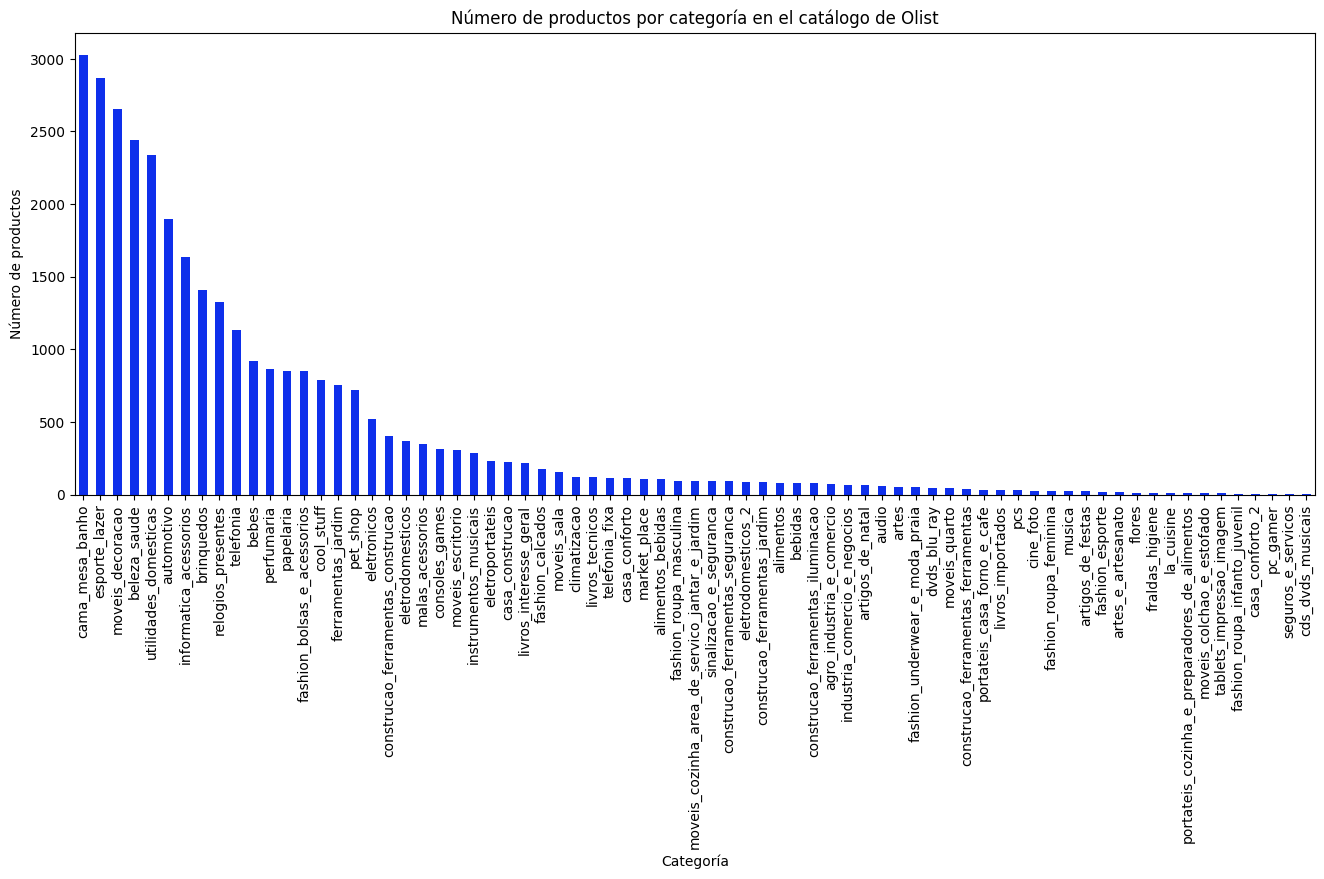

In [3]:
ax=conteo_categorias.plot(kind="bar",
                          color="#0e2feb",
                          title="Número de productos por categoría en el catálogo de Olist",
                          xlabel="Categoría",
                          ylabel="Número de productos",
                          figsize=(16,6)
                          )
plt.show()

**Respuesta:** `cama_mesa_banho`, `esporte_lazer` y `moveis_decoracao` son las categorías con más productos; después hay una cola larga de categorías con muy pocos productos. (Nota: 610 productos no tienen categoría y `value_counts()` los omite.)

## 2. Las 10 categorías principales
**Pregunta:** ¿Cuáles son las categorías con mayor presencia en el catálogo?  
**Operación:** `head(10)` sobre el conteo ya ordenado.  
**Gráfica:** barras horizontales (los nombres largos se leen mejor). Con `barh` la primera categoría queda abajo, por eso ordenamos con `sort_values()` de menor a mayor: así la más grande queda arriba.

In [4]:
top10_categorias=conteo_categorias.head(10).sort_values()
display(top10_categorias)

product_category_name
telefonia                 1134
relogios_presentes        1329
brinquedos                1411
informatica_acessorios    1639
automotivo                1900
utilidades_domesticas     2335
beleza_saude              2444
moveis_decoracao          2657
esporte_lazer             2867
cama_mesa_banho           3029
Name: count, dtype: int64

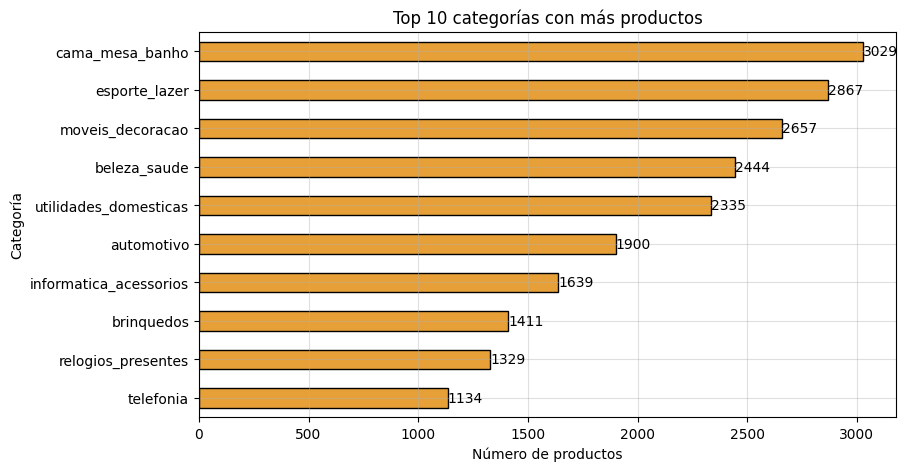

In [5]:
ax=top10_categorias.plot(kind="barh",
                         color="#e7a038",
                         edgecolor="black",
                         title="Top 10 categorías con más productos",
                         xlabel="Número de productos",
                         ylabel="Categoría",
                         figsize=(9,5)
                         )
ax.bar_label(ax.containers[0])
plt.grid(alpha=0.4)
plt.show()

## 3. Distribución de productos (pie chart)
**Pregunta:** ¿Qué proporción del catálogo está concentrada en las principales categorías?  
**Operación:** tomar las 5 principales y sumar todas las demás en "Otros".

In [6]:
top5=conteo_categorias.head(5)
otros=conteo_categorias.iloc[5:].sum()

distribucion=top5.copy()
distribucion["Otros"]=otros
display(distribucion)

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
Otros                    19009
Name: count, dtype: int64

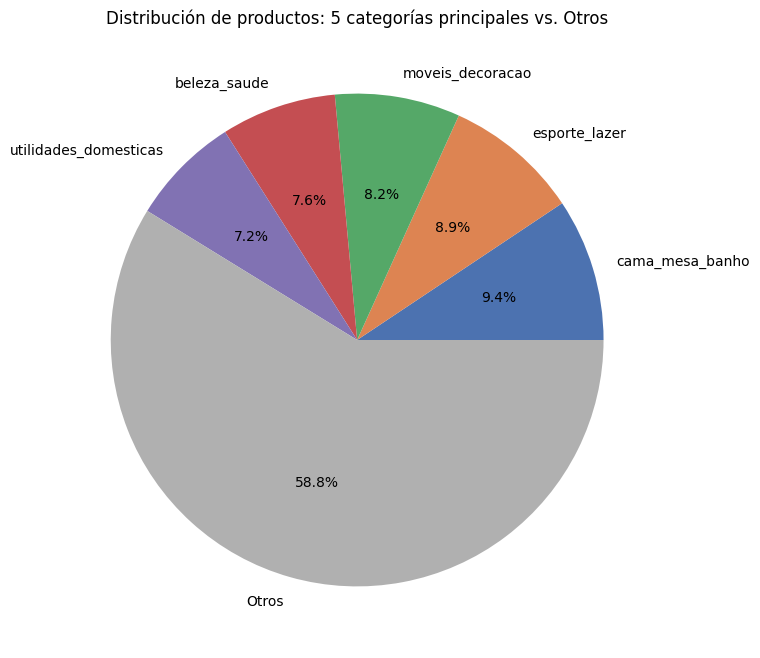

In [7]:
ax=distribucion.plot(kind="pie",
                     colors=["#4c72b0","#dd8452","#55a868","#c44e52","#8172b3","#b0b0b0"],
                     autopct="%1.1f%%",
                     title="Distribución de productos: 5 categorías principales vs. Otros",
                     ylabel="",
                     figsize=(8,8)
                     )
plt.show()

**Respuesta:** las 5 categorías principales concentran aproximadamente 41 % del catálogo; el 59 % restante se reparte entre las otras 68 categorías.

## 4. Clientes por estado
**Pregunta:** ¿Qué estados concentran la mayor cantidad de clientes?  
**Variable:** `customer_state`. Se cuenta cada registro de `customer_id` (un cliente por pedido en esta tabla).

In [8]:
clientes_estado=clientes["customer_state"].value_counts().sort_values()
display(clientes_estado)

customer_state
RR       46
AP       68
AC       81
AM      148
RO      253
TO      280
SE      350
AL      413
RN      485
PI      495
PB      536
MS      715
MA      747
MT      907
PA      975
CE     1336
PE     1652
GO     2020
ES     2033
DF     2140
BA     3380
SC     3637
PR     5045
RS     5466
MG    11635
RJ    12852
SP    41746
Name: count, dtype: int64

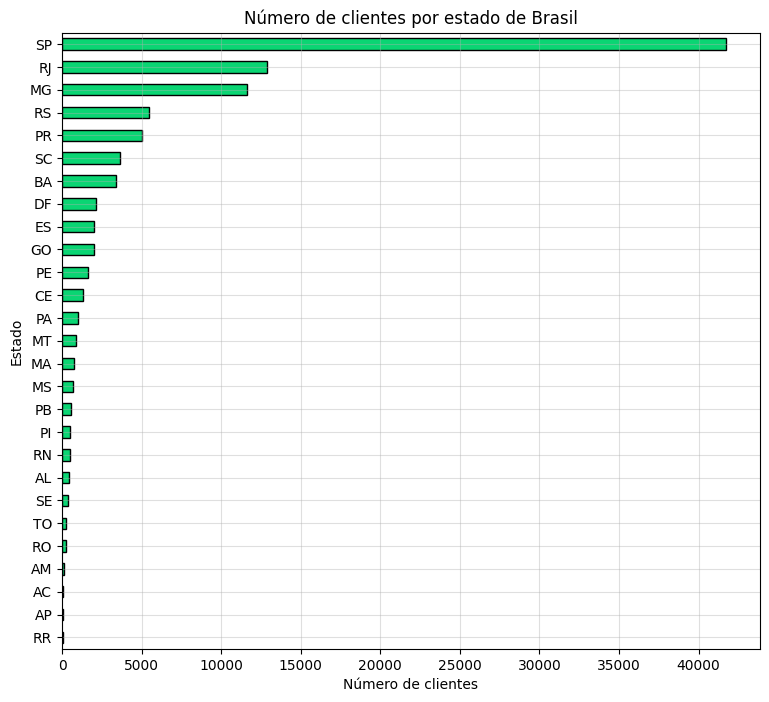

In [9]:
ax=clientes_estado.plot(kind="barh",
                        color="#0ad573",
                        edgecolor="black",
                        title="Número de clientes por estado de Brasil",
                        xlabel="Número de clientes",
                        ylabel="Estado",
                        figsize=(9,8)
                        )
plt.grid(alpha=0.4)
plt.show()

**Respuesta:** São Paulo (SP) concentra por mucho la mayor cantidad de clientes, seguido de Río de Janeiro (RJ) y Minas Gerais (MG).

## 5. Estados principales (pie chart)
**Pregunta:** ¿Qué tan concentrada está la base de clientes geográficamente?

In [10]:
top5_estados=clientes_estado.sort_values(ascending=False).head(5)
otros_estados=clientes_estado.sort_values(ascending=False).iloc[5:].sum()

dist_estados=top5_estados.copy()
dist_estados["Otros"]=otros_estados
display(dist_estados)

customer_state
SP       41746
RJ       12852
MG       11635
RS        5466
PR        5045
Otros    22697
Name: count, dtype: int64

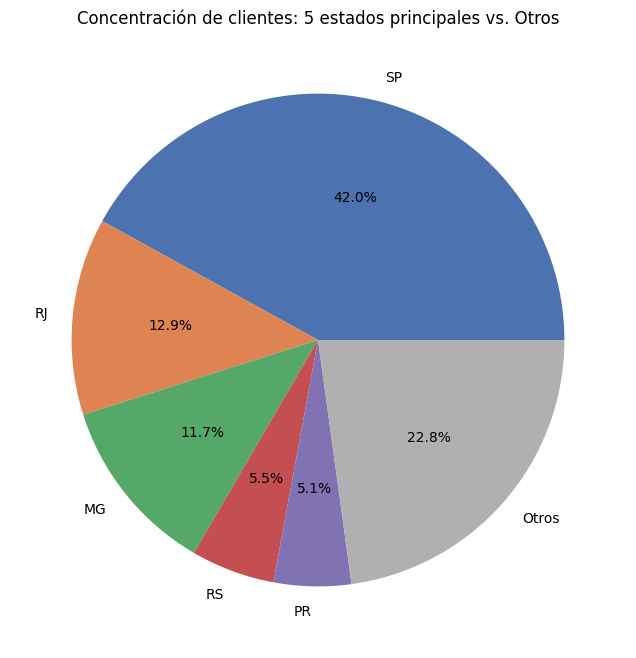

In [11]:
ax=dist_estados.plot(kind="pie",
                     colors=["#4c72b0","#dd8452","#55a868","#c44e52","#8172b3","#b0b0b0"],
                     autopct="%1.1f%%",
                     title="Concentración de clientes: 5 estados principales vs. Otros",
                     ylabel="",
                     figsize=(8,8)
                     )
plt.show()

**Respuesta:** SP, RJ, MG, RS y PR suman cerca de 77 % de los clientes; solo SP representa alrededor de 42 %. La base de clientes está muy concentrada en el sur y sureste del país.

## 6. Métodos de pago
**Pregunta:** ¿Cuál es el método de pago más utilizado?  
**Variable:** `payment_type`. Cada fila de la tabla es un pago.

In [12]:
metodos=pagos["payment_type"].value_counts()
display(metodos)

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

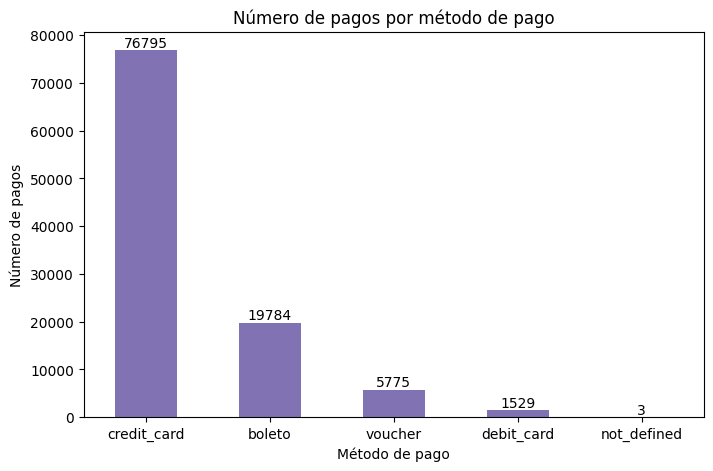

In [13]:
ax=metodos.plot(kind="bar",
                color="#8172b3",
                title="Número de pagos por método de pago",
                xlabel="Método de pago",
                ylabel="Número de pagos",
                rot=0,
                figsize=(8,5)
                )
ax.bar_label(ax.containers[0])
plt.show()

Ahora el pie chart con **exactamente la misma información**:

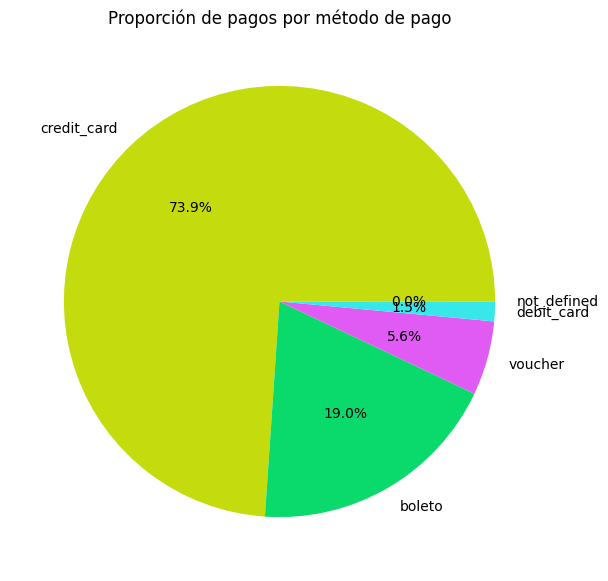

In [14]:
ax=metodos.plot(kind="pie",
                colors=["#c4dc0d","#0ad96b","#e05bf4","#38e7ea","#e7a038"],
                autopct="%1.1f%%",
                title="Proporción de pagos por método de pago",
                ylabel="",
                figsize=(7,7)
                )
plt.show()

**Respuesta:** la tarjeta de crédito (`credit_card`) es el método más usado (~74 % de los pagos), seguida de `boleto`.

**Reflexión:**
- *¿Cuál permite comparar mejor?* La **gráfica de barras**: comparar longitudes de barras alineadas es más preciso que comparar ángulos o áreas, y se notan bien las diferencias entre métodos pequeños (`voucher`, `debit_card`), que en el pie casi no se distinguen. Además `not_defined` (3 pagos) es invisible en el pie.
- *¿Cuál usaría para enfatizar la proporción?* El **pie chart**, porque muestra directamente que la tarjeta de crédito ocupa casi tres cuartas partes del total.

## 7. Número de cuotas
**Pregunta:** ¿Qué número de cuotas es el más frecuente?  
**Reto:** mostrar solo de 1 a 10 cuotas.  
**Operación:** `value_counts()` + `sort_index()` para ordenar por número de cuotas (no por frecuencia, porque el eje X es una escala numérica).

In [15]:
cuotas=pagos["payment_installments"].value_counts().sort_index()
cuotas_1_10=cuotas.loc[1:10]
display(cuotas_1_10)

payment_installments
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
Name: count, dtype: int64

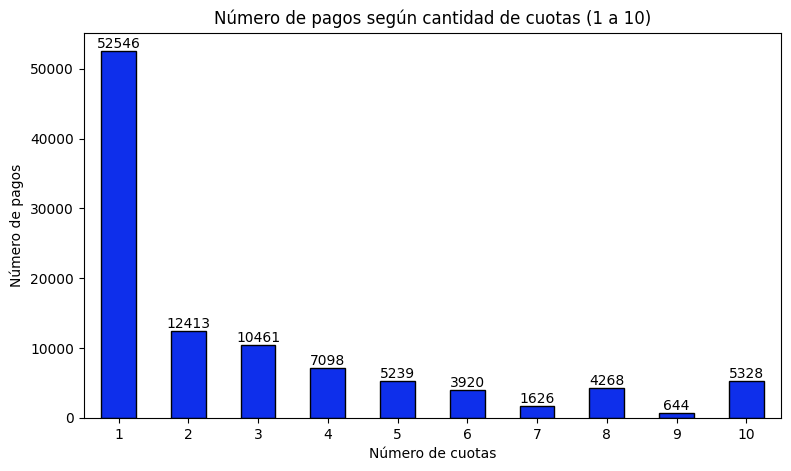

In [16]:
ax=cuotas_1_10.plot(kind="bar",
                    color="#0e2feb",
                    edgecolor="black",
                    title="Número de pagos según cantidad de cuotas (1 a 10)",
                    xlabel="Número de cuotas",
                    ylabel="Número de pagos",
                    rot=0,
                    figsize=(9,5)
                    )
ax.bar_label(ax.containers[0])
plt.show()

**Respuesta:** pagar en **1 cuota** (de contado) es lo más frecuente, con más de la mitad de los pagos; le siguen 2, 3 y 10 cuotas.

## 8. Comparando visualizaciones
Misma variable (`payment_type`), mismos datos, dos gráficas en una sola figura (`plt.subplots(1, 2)`).

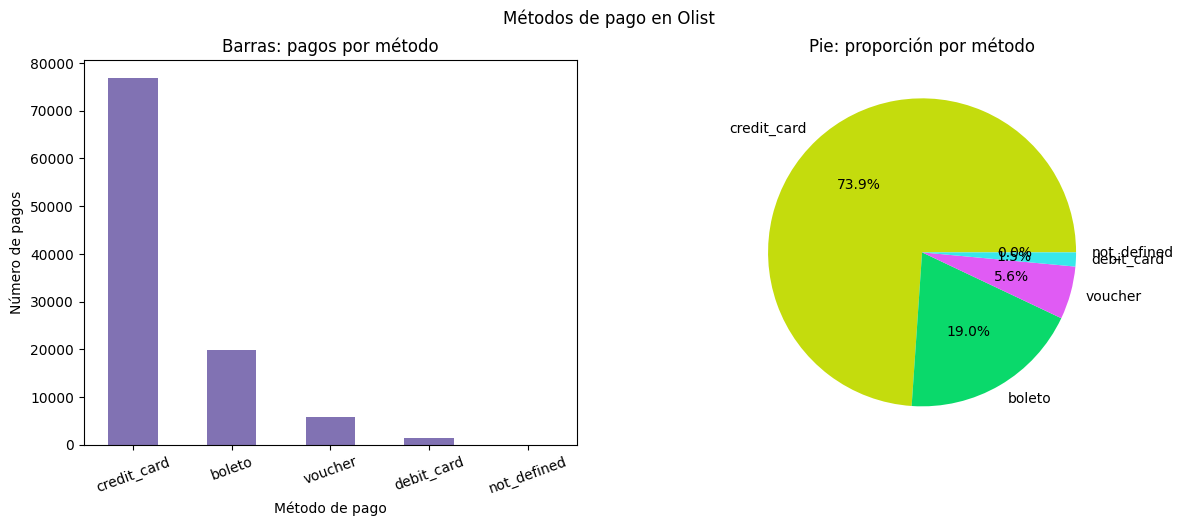

In [17]:
fig, ax=plt.subplots(1,2,figsize=(14,5))

#Gráfica de barras en el primer eje
metodos.plot(kind="bar",
             color="#8172b3",
             ax=ax[0],
             title="Barras: pagos por método",
             xlabel="Método de pago",
             ylabel="Número de pagos",
             rot=20
             )

#Pie chart en el segundo eje
metodos.plot(kind="pie",
             colors=["#c4dc0d","#0ad96b","#e05bf4","#38e7ea","#e7a038"],
             autopct="%1.1f%%",
             ax=ax[1],
             title="Pie: proporción por método",
             ylabel=""
             )

fig.suptitle("Métodos de pago en Olist")
plt.show()

**¿Cuál usaría en un reporte para comparar los métodos de pago?** La gráfica de barras: permite comparar valores exactos y se leen bien incluso las categorías pequeñas.

**¿Cuál usaría para enfatizar la proporción de cada método?** El pie chart, siempre que haya pocas categorías (aquí 4–5) y un método claramente dominante.